In [102]:
# Chargement des premières bibliothèques nécessaires
import pandas as pd
import numpy as np
import seaborn as sns
import plotly.express as px
import joblib as jb
import matplotlib.pyplot as plt

In [103]:
# Masquer les messages d'avertissement
import warnings
warnings.filterwarnings("ignore")

## Description des variables

Le jeu de données contient **5 507 annonces de voitures** décrites par **6 variables** : 5 variables explicatives et 1 variable cible (`Venant_Occasion`).

| Variable | Type | Description | Valeurs / plage observée |
|---|---|---|---|
| `Marque` | Catégorielle | Marque de la voiture | 46 marques (Ford, Kia, Hyundai, Mercedes-Benz, Toyota...) |
| `Année` | Numérique (discrète) | Année du véhicule | 1990 – 2024 (médiane = 2015) |
| `Boite_Vitesse` | Catégorielle | Type de boîte de vitesse | `Automatique`, `Manuelle`, `Tiptronic` |
| `Adresse` | Catégorielle | Quartier de l'annonce | 182 écritures dans le fichier brut, soit 85 adresses réelles après nettoyage (Almadies, VDN, Plateau...), toutes à Dakar |
| `Prix` | Numérique (continue) | Prix de la voiture | 1 – 779 414 131 (médiane = 7 800 000) |
| **`Venant_Occasion`** | Catégorielle | **Variable cible** : origine / état du véhicule | `Venant` (2 855 annonces), `D'occasion` (2 652 annonces) |

In [104]:
# Lecture des données et aperçu des 15 premières lignes
jeu_donnees = pd.read_csv("Car_Data.csv")
jeu_donnees.head(15)

,Marque,Année,Boite_Vitesse,Adresse,Prix,Venant_Occasion
0,Mitsubishi,2017,Automatique,"Liberte 6,Dakar",9750000,Venant
1,Ford,2009,Manuelle,"Yoff,Dakar",2500000,D'occasion
2,BMW,2015,Automatique,"Cité Damel,Dakar",15500000,D'occasion
3,Ford,2013,Automatique,"Almadies,Dakar",3800000,D'occasion
4,GMC,2014,Automatique,"Hlm,Dakar",7500000,Venant
5,Mitsubishi,2014,Manuelle,"VDN,Dakar",13500000,Venant
6,Peugeot,2015,Automatique,"Yoff,Dakar",6000000,Venant
7,Porsche,2018,Automatique,"Plateau,Dakar",25000000,Venant
8,Kia,2012,Automatique,"Parcelles Assainies,Dakar",5700000,D'occasion
9,Ford,2013,Automatique,"Liberte 6 extension,Dakar",5800000,D'occasion


In [105]:
# Nombre de lignes et de colonnes du jeu de données
jeu_donnees.shape

(5507, 6)

In [106]:
# Résumé des colonnes et de leurs types
jeu_donnees.info()

<class 'pandas.DataFrame'>
RangeIndex: 5507 entries, 0 to 5506
Data columns (total 6 columns):
 #   Column           Non-Null Count  Dtype
---  ------           --------------  -----
 0   Marque           5507 non-null   str  
 1   Année            5507 non-null   int64
 2   Boite_Vitesse    5507 non-null   str  
 3   Adresse          5507 non-null   str  
 4   Prix             5507 non-null   int64
 5   Venant_Occasion  5507 non-null   str  
dtypes: int64(2), str(4)
memory usage: 475.3 KB


### <font color = 'teal'>Exploration et preparation des données<font>

###### <font color = 'bisque'> Nettoyage de la colonne Adresse

In [107]:
# Compte des adresses distinctes avant nettoyage
# (une même adresse apparaît sous plusieurs écritures : espace en trop devant, ou après la virgule)
print(jeu_donnees['Adresse'].nunique())
jeu_donnees['Adresse'].unique()[:10]

182


<ArrowStringArray>
[          'Liberte 6,Dakar',                'Yoff,Dakar',
          'Cité Damel,Dakar',            'Almadies,Dakar',
                 'Hlm,Dakar',                 'VDN,Dakar',
             'Plateau,Dakar', 'Parcelles Assainies,Dakar',
 'Liberte 6 extension,Dakar',            'Colobane,Dakar']
Length: 10, dtype: str

In [108]:
# Normalisation de la colonne Adresse
# 1) retirer les espaces autour de la virgule et aux extrémités du texte
#    ex : ' Almadies,Dakar' et 'Almadies, Dakar' deviennent 'Almadies,Dakar'
jeu_donnees['Adresse'] = jeu_donnees['Adresse'].str.replace(r"\s*,\s*", ",", regex = True).str.strip()
# 2) unifier la seule adresse écrite avec deux casses différentes
jeu_donnees['Adresse'] = jeu_donnees['Adresse'].replace({'Lac rose,Dakar': 'Lac Rose,Dakar'})

In [109]:
# Compte des adresses distinctes après nettoyage
print(jeu_donnees['Adresse'].nunique())
jeu_donnees['Adresse'].unique()[:10]

85


<ArrowStringArray>
[          'Liberte 6,Dakar',                'Yoff,Dakar',
          'Cité Damel,Dakar',            'Almadies,Dakar',
                 'Hlm,Dakar',                 'VDN,Dakar',
             'Plateau,Dakar', 'Parcelles Assainies,Dakar',
 'Liberte 6 extension,Dakar',            'Colobane,Dakar']
Length: 10, dtype: str

###### <font color = 'bisque'> Selection des variables catégorielles et quantitatives

In [110]:
# Isoler les colonnes catégorielles
donnees_categorielles = jeu_donnees.select_dtypes(exclude = 'number')
donnees_categorielles

,Marque,Boite_Vitesse,Adresse,Venant_Occasion
0,Mitsubishi,Automatique,"Liberte 6,Dakar",Venant
1,Ford,Manuelle,"Yoff,Dakar",D'occasion
2,BMW,Automatique,"Cité Damel,Dakar",D'occasion
3,Ford,Automatique,"Almadies,Dakar",D'occasion
4,GMC,Automatique,"Hlm,Dakar",Venant
...,...,...,...,...
5502,Kia,Automatique,"Liberte 6 extension,Dakar",Venant
5503,Mitsubishi,Manuelle,"Castor,Dakar",D'occasion
5504,Ford,Automatique,"Cité Damel,Dakar",D'occasion
5505,Mitsubishi,Automatique,"VDN,Dakar",Venant


In [111]:
# Isoler les colonnes numériques
donnees_numeriques = jeu_donnees.select_dtypes(include = "number")
donnees_numeriques.head()

,Année,Prix
0,2017,9750000
1,2009,2500000
2,2015,15500000
3,2013,3800000
4,2014,7500000


###### <font color = 'bisque'> Exploration des variables catégorielles

In [112]:
# Statistiques descriptives des colonnes catégorielles
donnees_categorielles.describe()

,Marque,Boite_Vitesse,Adresse,Venant_Occasion
count,5507,5507,5507,5507
unique,46,3,85,2
top,Ford,Automatique,"Almadies,Dakar",Venant
freq,1391,4675,792,2855


In [113]:
# Fonction qui trace le diagramme en barres des effectifs d'une colonne
import plotly.express as px
def tracer_diagramme_barres(colonne):
    effectifs  = jeu_donnees[colonne].value_counts()
    graphique = px.bar(x = effectifs.index, y = effectifs.values, color =effectifs.index.astype(str) , text_auto = True)
    graphique.show()

In [114]:
for colonne in donnees_categorielles:
    tracer_diagramme_barres(colonne)

###### <font color = 'bisque'> Exploration des variables quantitatives

In [115]:
# Statistiques descriptives des colonnes numériques
donnees_numeriques.describe()

,Année,Prix
count,5507.000000,5.507000e+03
mean,2014.508444,1.110512e+07
std,3.089839,1.619639e+07
min,1990.000000,1.000000e+00
25%,2013.000000,4.600000e+06
50%,2015.000000,7.800000e+06
75%,2016.000000,1.250000e+07
max,2024.000000,7.794141e+08


In [116]:
# Diagramme en barres pour chaque colonne numérique
for colonne in donnees_numeriques:
    tracer_diagramme_barres(colonne)

In [117]:
# Fonction qui trace la boîte à moustaches d'une colonne
def tracer_boite_moustaches(colonne):
  plt.figure(figsize=(25,3))
  sns.boxplot(x=jeu_donnees[colonne])
  plt.show()

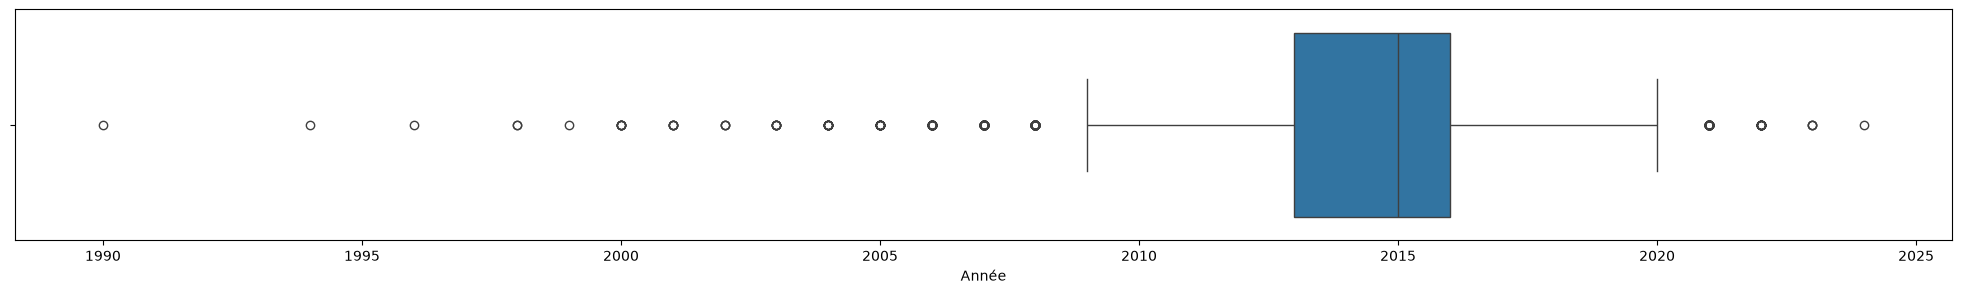

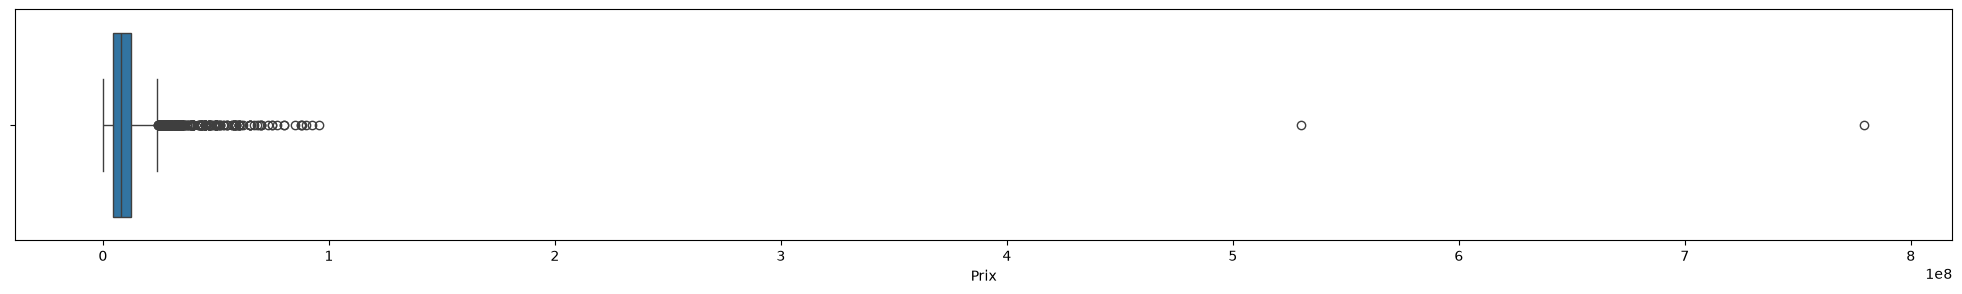

In [118]:
# Boîtes à moustaches de chaque colonne numérique
for colonne in donnees_numeriques:
    tracer_boite_moustaches(colonne)

###### <font color = 'bisque'> Preparation des données

In [119]:
# Contrôle des valeurs manquantes (aucune dans ce jeu de données)
jeu_donnees.isna().sum()

Marque             0
Année              0
Boite_Vitesse      0
Adresse            0
Prix               0
Venant_Occasion    0
dtype: int64

In [120]:
# Mémoriser les valeurs uniques de chaque variable catégorielle explicative (listes déroulantes de l'application)
valeurs_uniques_par_colonne = {colonne: np.unique(jeu_donnees[colonne]).tolist() for colonne in donnees_categorielles.columns if colonne != 'Venant_Occasion'}
# Enregistrement sur disque
jb.dump(valeurs_uniques_par_colonne, "./models/voiture_uniques_dict.joblib")
valeurs_uniques_par_colonne['Boite_Vitesse']

['Automatique', 'Manuelle', 'Tiptronic']

In [121]:
# Encodage des variables catégorielles
from sklearn.preprocessing import LabelEncoder

# Un encodeur par variable catégorielle (cible 'Venant_Occasion' incluse), rangés dans un dictionnaire
encodeurs_par_colonne = {}
for colonne in donnees_categorielles.columns:
    encodeur_colonne = LabelEncoder()
    jeu_donnees[colonne] = encodeur_colonne.fit_transform(jeu_donnees[colonne])
    encodeurs_par_colonne[colonne] = encodeur_colonne

# Classes de la variable cible, dans l'ordre de leurs codes 0 et 1
noms_classes = encodeurs_par_colonne['Venant_Occasion'].classes_
noms_classes

array(["D'occasion", 'Venant'], dtype=object)

In [122]:
# Enregistrement des encodeurs
jb.dump(encodeurs_par_colonne, "./models/voiture_encoders_v2.joblib")

['./models/voiture_encoders_v2.joblib']

In [123]:
from sklearn.impute import KNNImputer
# Fonction de remplacement des valeurs aberrantes par imputation
# (fonction définie ici ; elle est appelée dans la cellule suivante)
def traiter_valeurs_aberrantes(jeu_donnees, colonne, n_neighbors=5):
    # Détection des valeurs aberrantes (méthode de l'écart interquartile)
    quartile_1 = jeu_donnees[colonne].quantile(0.25)
    quartile_3 = jeu_donnees[colonne].quantile(0.75)
    ecart_interquartile = quartile_3 - quartile_1
    borne_inferieure = quartile_1 - 1.5 * ecart_interquartile
    borne_superieure = quartile_3 + 1.5 * ecart_interquartile

    # Les valeurs hors bornes passent à NaN pour que le KNNImputer les remplace
    jeu_donnees.loc[(jeu_donnees[colonne] < borne_inferieure) | (jeu_donnees[colonne] > borne_superieure), colonne] = np.nan
    # n_neighbors : nombre de voisins utilisés pour calculer la valeur de remplacement
    imputateur_knn = KNNImputer(n_neighbors=n_neighbors)
    jeu_donnees[:] = imputateur_knn.fit_transform(jeu_donnees)

In [124]:
# Traitement des valeurs aberrantes, colonne par colonne
for colonne in donnees_numeriques :
    traiter_valeurs_aberrantes(jeu_donnees,colonne)

In [125]:
# Séparer les variables explicatives de la variable cible
caracteristiques = jeu_donnees.drop('Venant_Occasion', axis = 1).values
cible = jeu_donnees.Venant_Occasion.values

# Ordre des variables explicatives (à respecter au moment des prédictions)
noms_variables_explicatives = jeu_donnees.drop('Venant_Occasion', axis = 1).columns.tolist()
jb.dump(noms_variables_explicatives, "./models/voiture_features.joblib")
noms_variables_explicatives

['Marque', 'Année', 'Boite_Vitesse', 'Adresse', 'Prix']

In [126]:
# Découpage des données en entraînement, validation et test
# entraînement (80 %), validation (10 %) et test (10 %)
# entraînement : pour apprendre ; validation : pour comparer les modèles ; test : pour juger le meilleur modèle

from sklearn.model_selection import train_test_split
x_entrainement, x_validation_test, y_entrainement, y_validation_test = train_test_split(caracteristiques, cible, train_size = 0.8, random_state = 42)
x_validation, x_test, y_validation, y_test = train_test_split(x_validation_test, y_validation_test, train_size = 0.5, random_state = 42)

In [127]:
# Mise à l'échelle : ajustée sur l'entraînement uniquement, puis appliquée à la validation et au test
from sklearn.preprocessing import MinMaxScaler # Z = (X - Xmin) / (Xmax - Xmin)
mise_a_echelle = MinMaxScaler()
x_entrainement = mise_a_echelle.fit_transform(x_entrainement)
x_validation = mise_a_echelle.transform(x_validation)
x_test = mise_a_echelle.transform(x_test)
x_entrainement[:5]

array([[0.62222222, 0.90909091, 0.        , 0.01190476, 0.84999999],
       [0.73333333, 0.        , 0.        , 0.75      , 0.17499997],
       [0.6       , 0.45454545, 0.        , 0.79761905, 0.39583331],
       [0.28888889, 0.72727273, 0.        , 0.92857143, 0.58333332],
       [0.77777778, 0.45454545, 0.        , 0.0952381 , 0.2583333 ]])

In [128]:
# Enregistrement du normaliseur
jb.dump(mise_a_echelle, "./models/voiture_scaler.joblib")

['./models/voiture_scaler.joblib']

### <font color = 'teal'>Fonctions d'évaluation<font>

In [129]:
# Fonction d'évaluation sur les données de validation
from sklearn.metrics import f1_score, accuracy_score
def evaluer_modele(modele):
  y_predit = modele.predict(x_validation)
  exactitude = accuracy_score(y_validation, y_predit)
  score_f1 = f1_score(y_validation, y_predit, average='weighted')
  return exactitude, score_f1

In [130]:
# Imports pour la matrice de confusion
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
# Prédictions du modèle sur les données de validation
def tracer_matrice_confusion(modele):

    y_predit = modele.predict(x_validation)
    # Calcul de la matrice de confusion
    matrice_confusion = confusion_matrix(y_validation, y_predit, labels=np.arange(len(noms_classes)))

    # Mise en forme avec ConfusionMatrixDisplay
    affichage = ConfusionMatrixDisplay(confusion_matrix=matrice_confusion,
                                  display_labels=noms_classes)
    affichage.plot() # Tracer la matrice
    plt.title('Matrice de confusion') # Titre du graphique
    plt.show() # Afficher le graphique

### <font color = 'teal'>Logistic Regression<font>

###### <font color = 'bisque'> Recherche des paramètre optimaux

In [131]:
from sklearn.model_selection import GridSearchCV, KFold
# Recherche des meilleurs paramètres pour la régression logistique
from sklearn.linear_model import LogisticRegression
validation_croisee = KFold(n_splits = 5, shuffle =True, random_state= 42)
# Grille des paramètres à tester
grille_reg_logistique = {"C":np.logspace(-3,3,10),"penalty": ['l1','l2']}
# Création du modèle de régression logistique (solveur 'saga' : accepte les pénalités l1 et l2)
reg_logistique = LogisticRegression(solver = 'saga', max_iter = 2000)
# Création de la recherche sur grille
recherche_reg_logistique = GridSearchCV(reg_logistique, grille_reg_logistique, cv = validation_croisee, n_jobs = -1)
# Lancer la recherche
recherche_reg_logistique.fit(x_entrainement, y_entrainement)

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",LogisticRegre...solver='saga')
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'C': array([1.0000...00000000e+03]), 'penalty': ['l1', 'l2']}"
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",KFold(n_split... shuffle=True)
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",None
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example<sphx_glr_auto_examples_model_selection_plot_grid_search_refit_callable.py>`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",True
,"verbose verbose: int, default=0Control

In [132]:
# Afficher les meilleurs paramètres
recherche_reg_logistique.best_params_

{'C': np.float64(0.021544346900318832), 'penalty': 'l2'}

###### <font color = 'bisque'> Entrainement du modèle

In [133]:
# Récupérer le meilleur modèle (déjà entraîné sur l'entraînement par GridSearchCV)
modele_reg_logistique = recherche_reg_logistique.best_estimator_

###### <font color = 'bisque'> Evaluation du modèle

In [134]:
# Exactitude (accuracy) et score F1 sur les données de validation
exactitude_reg_logistique ,f1_reg_logistique = evaluer_modele(modele_reg_logistique)
print(f"accuracy : {exactitude_reg_logistique} -------F1-Score : {f1_reg_logistique}")

accuracy : 0.7931034482758621 -------F1-Score : 0.7931034482758621


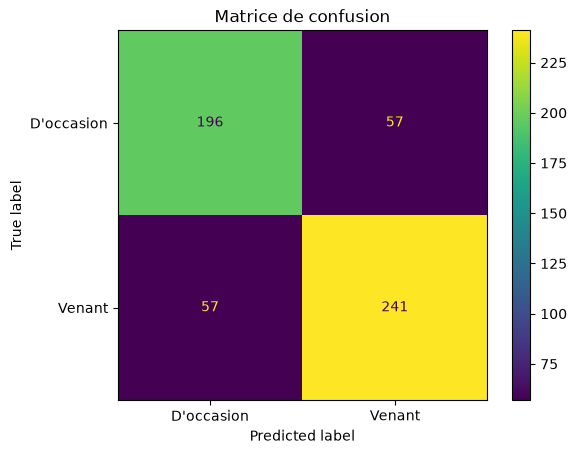

In [135]:
# Matrice de confusion sur la validation
tracer_matrice_confusion(modele_reg_logistique)

### <font color = 'teal'>Decision Tree<font>

###### <font color = 'bisque'> Recherche des paramètre optimaux

In [136]:
# Recherche des meilleurs paramètres pour l'arbre de décision
from sklearn.tree import DecisionTreeClassifier
validation_croisee = KFold(n_splits = 5, shuffle =True, random_state= 42)

# Grille des paramètres à tester
grille_arbre = {'criterion':['gini','entropy'],'max_depth':np.arange(3,15)}
# Création du modèle d'arbre de décision
arbre = DecisionTreeClassifier(random_state = 42)
# Création de la recherche sur grille
recherche_arbre = GridSearchCV(arbre, grille_arbre, cv = validation_croisee, n_jobs = -1)
# Lancer l'entraînement
recherche_arbre.fit(x_entrainement, y_entrainement)

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",DecisionTreeC...ndom_state=42)
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'criterion': ['gini', 'entropy'], 'max_depth': array([ 3, 4..., 12, 13, 14])}"
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",KFold(n_split... shuffle=True)
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",None
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example<sphx_glr_auto_examples_model_selection_plot_grid_search_refit_callable.py>`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",True
,"verbose verbose: int, 

In [137]:
# Afficher les meilleurs paramètres
recherche_arbre.best_params_

{'criterion': 'entropy', 'max_depth': np.int64(4)}

###### <font color = 'bisque'> Entrainement du modèle

In [138]:
# Récupérer le meilleur modèle
modele_arbre = recherche_arbre.best_estimator_

###### <font color = 'bisque'> Evaluation du modèle

In [139]:
# Exactitude (accuracy) et score F1 sur les données de validation
exactitude_arbre ,f1_arbre = evaluer_modele(modele_arbre)
print(f"accuracy : {exactitude_arbre} -------F1-Score : {f1_arbre}")

accuracy : 0.8112522686025408 -------F1-Score : 0.8104326569742984


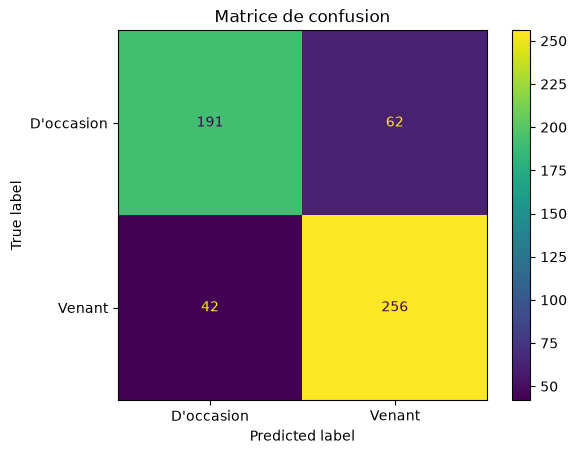

In [140]:
# Matrice de confusion sur la validation
tracer_matrice_confusion(modele_arbre)

### <font color = 'teal'>Random Forest<font>

In [141]:
# Recherche des meilleurs paramètres pour la forêt aléatoire
from sklearn.ensemble import RandomForestClassifier
# Grille des paramètres à tester
grille_foret = {
    'n_estimators': list(np.arange(10,100,10)),
    'max_depth' : list(np.arange(3,15)),
    'criterion' :['gini', 'entropy']
}
validation_croisee = KFold(n_splits = 5, shuffle =True, random_state= 42)

# Création du modèle de forêt aléatoire
foret = RandomForestClassifier(random_state = 42)
# Création de la recherche sur grille
recherche_foret = GridSearchCV(estimator=foret, param_grid=grille_foret, cv= validation_croisee, n_jobs = -1)
# Lancer l'entraînement
recherche_foret.fit(x_entrainement, y_entrainement)

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",RandomForestC...ndom_state=42)
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'criterion': ['gini', 'entropy'], 'max_depth': [np.int64(3), np.int64(4), ...], 'n_estimators': [np.int64(10), np.int64(20), ...]}"
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",KFold(n_split... shuffle=True)
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",None
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example<sphx_glr_auto_examples_model_selection_plot_grid_search_refit_callable.py>`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Suppo

In [142]:
# Afficher les meilleurs paramètres
recherche_foret.best_params_

{'criterion': 'gini', 'max_depth': np.int64(9), 'n_estimators': np.int64(60)}

In [143]:
# Récupérer le meilleur modèle
modele_foret = recherche_foret.best_estimator_

##### <font color ='bisque'>Evaluation du Random Forest<font>

In [144]:
# Exactitude (accuracy) et score F1 sur les données de validation
exactitude_foret ,f1_foret = evaluer_modele(modele_foret)
print(f"accuracy : {exactitude_foret} -------F1-Score : {f1_foret}")

accuracy : 0.8058076225045372 -------F1-Score : 0.8041275464763663


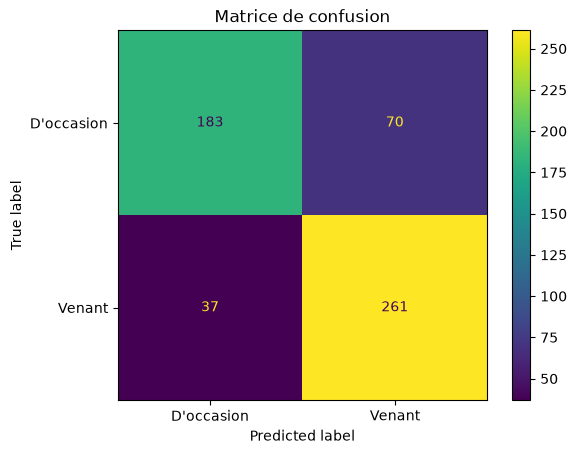

In [145]:
# Matrice de confusion sur la validation
tracer_matrice_confusion(modele_foret)

### <font color = 'teal'>Comparaison des modèles<font>

In [146]:
# Diagrammes comparant les performances
noms_modeles = ['LG', 'TREE','RF']
liste_exactitudes = [exactitude_reg_logistique, exactitude_arbre, exactitude_foret]
liste_f1 = [f1_reg_logistique,f1_arbre, f1_foret]
liste_resultats = [liste_exactitudes, liste_f1]

for indice in range(2):

    graphique = px.bar(y = noms_modeles, x = liste_resultats[indice], color = noms_modeles, text_auto = True)
    graphique.show()

### <font color = 'teal'>Sélection et sauvegarde du modèle le plus performant<font>

In [147]:
# Le modèle retenu est celui qui a la meilleure exactitude sur la validation
modeles = {'LG': modele_reg_logistique, 'TREE': modele_arbre, 'RF': modele_foret}
nom_meilleur_modele = noms_modeles[int(np.argmax(liste_exactitudes))]
meilleur_modele = modeles[nom_meilleur_modele]
print(f"Modèle le plus performant : {nom_meilleur_modele} (accuracy validation = {max(liste_exactitudes):.4f})")

Modèle le plus performant : TREE (accuracy validation = 0.8113)


In [148]:
# Enregistrement du meilleur modèle
jb.dump(meilleur_modele, "./models/voiture_model.joblib")

['./models/voiture_model.joblib']

### <font color ='bisque'>Tester le modèle le plus performant<font>

In [149]:
# Évaluation du modèle retenu sur les données de test
from sklearn.metrics import classification_report
y_predit_test = meilleur_modele.predict(x_test)
print(f"accuracy (test) : {accuracy_score(y_test, y_predit_test):.4f}")
print(classification_report(y_test, y_predit_test, target_names = noms_classes))

accuracy (test) : 0.7840
              precision    recall  f1-score   support

  D'occasion       0.81      0.74      0.77       274
      Venant       0.76      0.83      0.79       277

    accuracy                           0.78       551
   macro avg       0.79      0.78      0.78       551
weighted avg       0.79      0.78      0.78       551



In [150]:
# Extrait des 10 premiers exemples de test
x_test_extrait = x_test[:10]
y_test_extrait = y_test[:10]

# Prédictions sur cet extrait
y_pred_extrait = meilleur_modele.predict(x_test_extrait)
# Retrouver les libellés d'origine à partir des codes
libelles_predits = encodeurs_par_colonne['Venant_Occasion'].inverse_transform(y_pred_extrait)
libelles_reels = encodeurs_par_colonne['Venant_Occasion'].inverse_transform(y_test_extrait)

for indice in range(10):
    print(f"Prédiction {indice + 1} : {libelles_predits[indice]} -- Réel : {libelles_reels[indice]}")

Prédiction 1 : D'occasion -- Réel : D'occasion
Prédiction 2 : Venant -- Réel : Venant
Prédiction 3 : D'occasion -- Réel : D'occasion
Prédiction 4 : Venant -- Réel : Venant
Prédiction 5 : D'occasion -- Réel : Venant
Prédiction 6 : D'occasion -- Réel : D'occasion
Prédiction 7 : Venant -- Réel : Venant
Prédiction 8 : Venant -- Réel : D'occasion
Prédiction 9 : D'occasion -- Réel : Venant
Prédiction 10 : D'occasion -- Réel : D'occasion
